In [5]:
import pandas as pd
test = pd.read_csv("healthcare-dataset-stroke-data.csv")
test.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [6]:
import pandas as pd
train = pd.read_csv("healthcare-dataset-stroke-data.csv")
train.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# Menampilkan ringkasan informasi dari dataset

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


# Menampilkan statistik deskriptif dari dataset

In [8]:
train.describe(include="all")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


# Memeriksa jumlah nilai yang hilang di setiap kolom

In [9]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

bmi    201
dtype: int64

# Mengatasi missing value

In [10]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik

In [11]:
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# Contoh mengisi nilai yang hilang dengan modus untuk kolom kategorikal

In [12]:
categorical_features = train[less].select_dtypes(exclude=['number']).columns

for column in categorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

# Menghapus kolom dengan terlalu banyak nilai yang hilang

In [13]:
df = train.drop(columns=over)

In [14]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

# Mengatasi Outliers

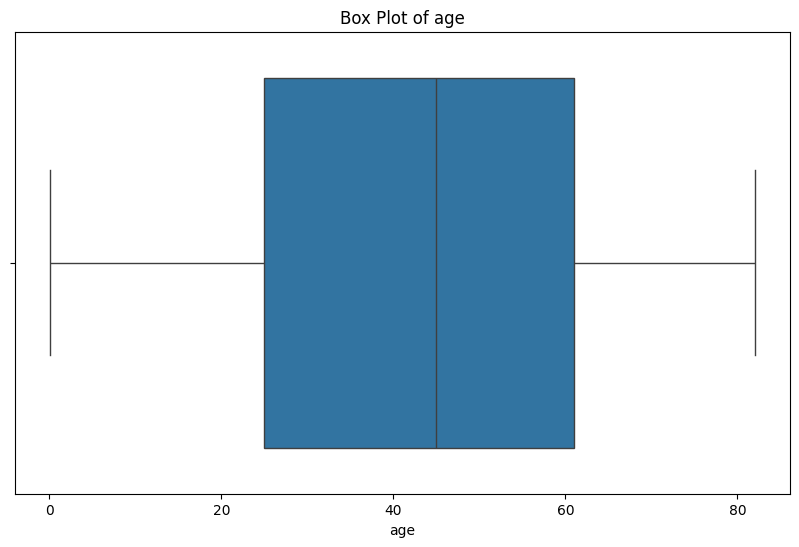

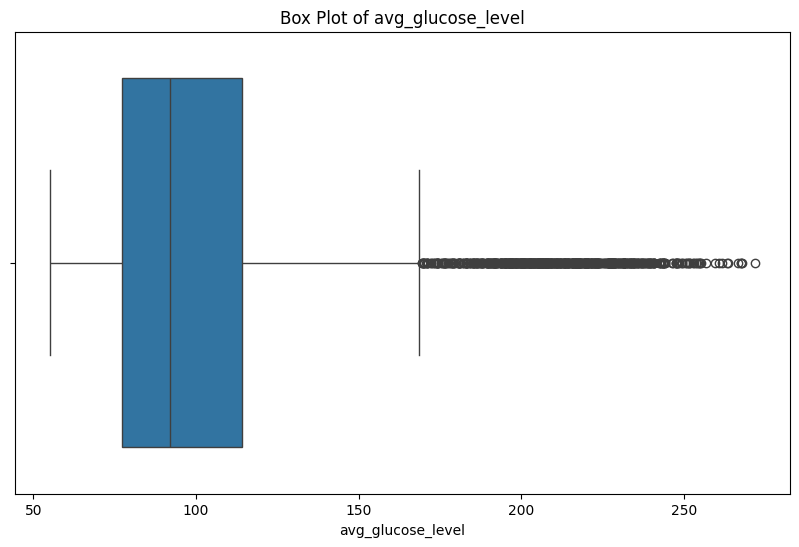

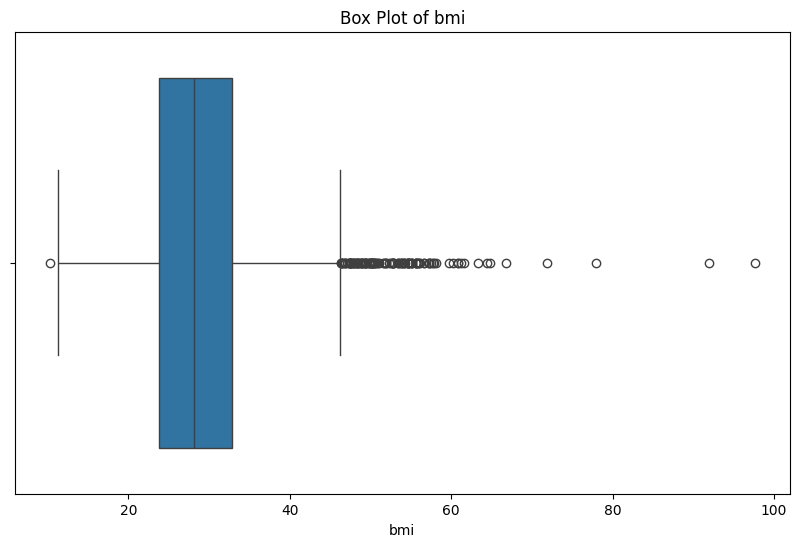

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numeric_features = ['age', 'avg_glucose_level', 'bmi']

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

# Mengidentifikasi outliers menggunakan IQR

In [16]:
numeric_features = ['age', 'avg_glucose_level', 'bmi']

Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

age                  36.000
avg_glucose_level    36.845
bmi                   9.000
dtype: float64


# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers

In [17]:
condition = ~(
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 + 1.5 * IQR))
).any(axis=1)

df_filtered = df.loc[condition]

print("Jumlah baris sebelum filtering:", df.shape[0])
print("Jumlah baris setelah filtering:", df_filtered.shape[0])
print("Jumlah kasus stroke sebelum:", df['stroke'].sum())
print("Jumlah kasus stroke setelah:", df_filtered['stroke'].sum())

Jumlah baris sebelum filtering: 5110
Jumlah baris setelah filtering: 4391
Jumlah kasus stroke sebelum: 249
Jumlah kasus stroke setelah: 165


# Mengganti outliers dengan nilai median

In [18]:
for column in numeric_features:
    Q1_col = df[column].quantile(0.25)
    Q3_col = df[column].quantile(0.75)
    IQR_col = Q3_col - Q1_col

    lower_bound = Q1_col - 1.5 * IQR_col
    upper_bound = Q3_col + 1.5 * IQR_col

    median = df[column].median()

    df[column] = df[column].apply(
        lambda x: median if x < lower_bound or x > upper_bound else x
    )

In [19]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik

In [20]:
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# Histogram Sebelum Standardisasi

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

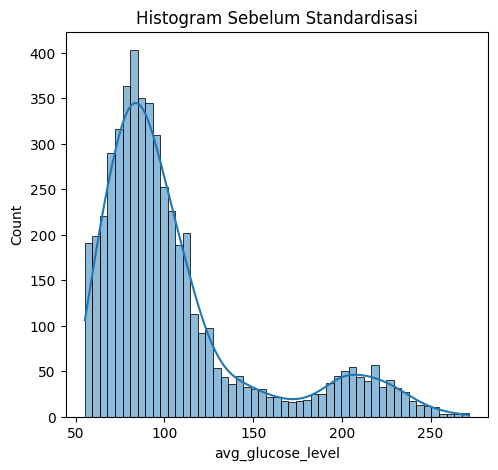

In [21]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[1]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

# Histogram Setelah Standardisasi

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

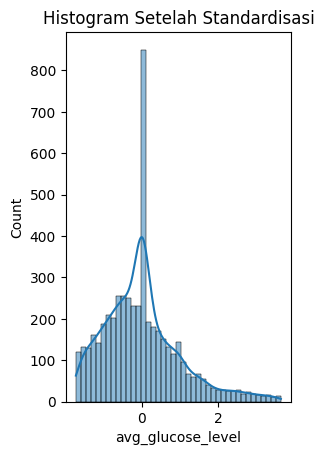

In [22]:
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[1]], kde=True)
plt.title("Histogram Setelah Standardisasi")

# Mengidentifikasi baris duplikat

In [23]:
duplicates = df.duplicated()

print("Jumlah baris duplikat:", duplicates.sum())
print("Baris duplikat:")
print(df[duplicates])

Jumlah baris duplikat: 0
Baris duplikat:
Empty DataFrame
Columns: [id, gender, age, hypertension, heart_disease, ever_married, work_type, Residence_type, avg_glucose_level, bmi, smoking_status, stroke]
Index: []


In [24]:
print("Jumlah duplikat tanpa kolom id:", df.drop(columns='id').duplicated().sum())

Jumlah duplikat tanpa kolom id: 0


# Menghapus baris duplikat

In [25]:
jumlah_sebelum = df.shape[0]
df = df.drop_duplicates()

print("Jumlah baris sebelum:", jumlah_sebelum)
print("Jumlah baris setelah:", df.shape[0])
print("DataFrame setelah menghapus duplikat:")
df.head()

Jumlah baris sebelum: 5110
Jumlah baris setelah: 5110
DataFrame setelah menghapus duplikat:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,1.051434,0,1,Yes,Private,Urban,0.018619,1.275665,formerly smoked,1
1,51676,Female,0.786070,0,0,Yes,Self-employed,Rural,0.018619,-0.022712,never smoked,1
2,31112,Male,1.626390,0,1,Yes,Private,Rural,0.680667,0.649389,never smoked,1
3,60182,Female,0.255342,0,0,Yes,Private,Urban,0.018619,0.939614,smokes,1
4,1665,Female,1.582163,1,0,Yes,Self-employed,Rural,0.018619,-0.648988,never smoked,1


In [26]:
category_features = df.select_dtypes(exclude=['number']).columns
df[category_features]

,gender,ever_married,work_type,Residence_type,smoking_status
0,Male,Yes,Private,Urban,formerly smoked
1,Female,Yes,Self-employed,Rural,never smoked
2,Male,Yes,Private,Rural,never smoked
3,Female,Yes,Private,Urban,smokes
4,Female,Yes,Self-employed,Rural,never smoked
...,...,...,...,...,...
5105,Female,Yes,Private,Urban,never smoked
5106,Female,Yes,Self-employed,Urban,never smoked
5107,Female,Yes,Self-employed,Rural,never smoked
5108,Male,Yes,Private,Rural,formerly smoked


In [27]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,1.051434,0,1,0.018619,1.275665,1,False,True,False,...,False,True,False,False,False,True,False,True,False,False
1,51676,0.786070,0,0,0.018619,-0.022712,1,True,False,False,...,False,False,True,False,True,False,False,False,True,False
2,31112,1.626390,0,1,0.680667,0.649389,1,False,True,False,...,False,True,False,False,True,False,False,False,True,False
3,60182,0.255342,0,0,0.018619,0.939614,1,True,False,False,...,False,True,False,False,False,True,False,False,False,True
4,1665,1.582163,1,0,0.018619,-0.648988,1,True,False,False,...,False,False,True,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,1.626390,1,0,-0.365118,-0.022712,0,True,False,False,...,False,True,False,False,False,True,False,False,True,False
5106,44873,1.670617,0,0,1.590128,1.795015,0,True,False,False,...,False,False,True,False,False,True,False,False,True,False
5107,19723,-0.363842,0,0,-0.400968,0.359163,0,True,False,False,...,False,False,True,False,True,False,False,False,True,False
5108,37544,0.343796,0,0,3.528392,-0.404588,0,False,True,False,...,False,True,False,False,True,False,False,True,False,False


In [28]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder

In [29]:
label_encoder = LabelEncoder()
df_lencoder = df.copy()

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil

In [30]:
df_lencoder

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,1.051434,0,1,1,2,1,0.018619,1.275665,1,1
1,51676,0,0.786070,0,0,1,3,0,0.018619,-0.022712,2,1
2,31112,1,1.626390,0,1,1,2,0,0.680667,0.649389,2,1
3,60182,0,0.255342,0,0,1,2,1,0.018619,0.939614,3,1
4,1665,0,1.582163,1,0,1,3,0,0.018619,-0.648988,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,0,1.626390,1,0,1,2,1,-0.365118,-0.022712,2,0
5106,44873,0,1.670617,0,0,1,3,1,1.590128,1.795015,2,0
5107,19723,0,-0.363842,0,0,1,3,0,-0.400968,0.359163,2,0
5108,37544,1,0.343796,0,0,1,2,0,3.528392,-0.404588,1,0


In [31]:
df_lencoder.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,1.051434,0,1,1,2,1,0.018619,1.275665,1,1
1,51676,0,0.786070,0,0,1,3,0,0.018619,-0.022712,2,1
2,31112,1,1.626390,0,1,1,2,0,0.680667,0.649389,2,1
3,60182,0,0.255342,0,0,1,2,1,0.018619,0.939614,3,1
4,1665,0,1.582163,1,0,1,3,0,0.018619,-0.648988,2,1


In [32]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


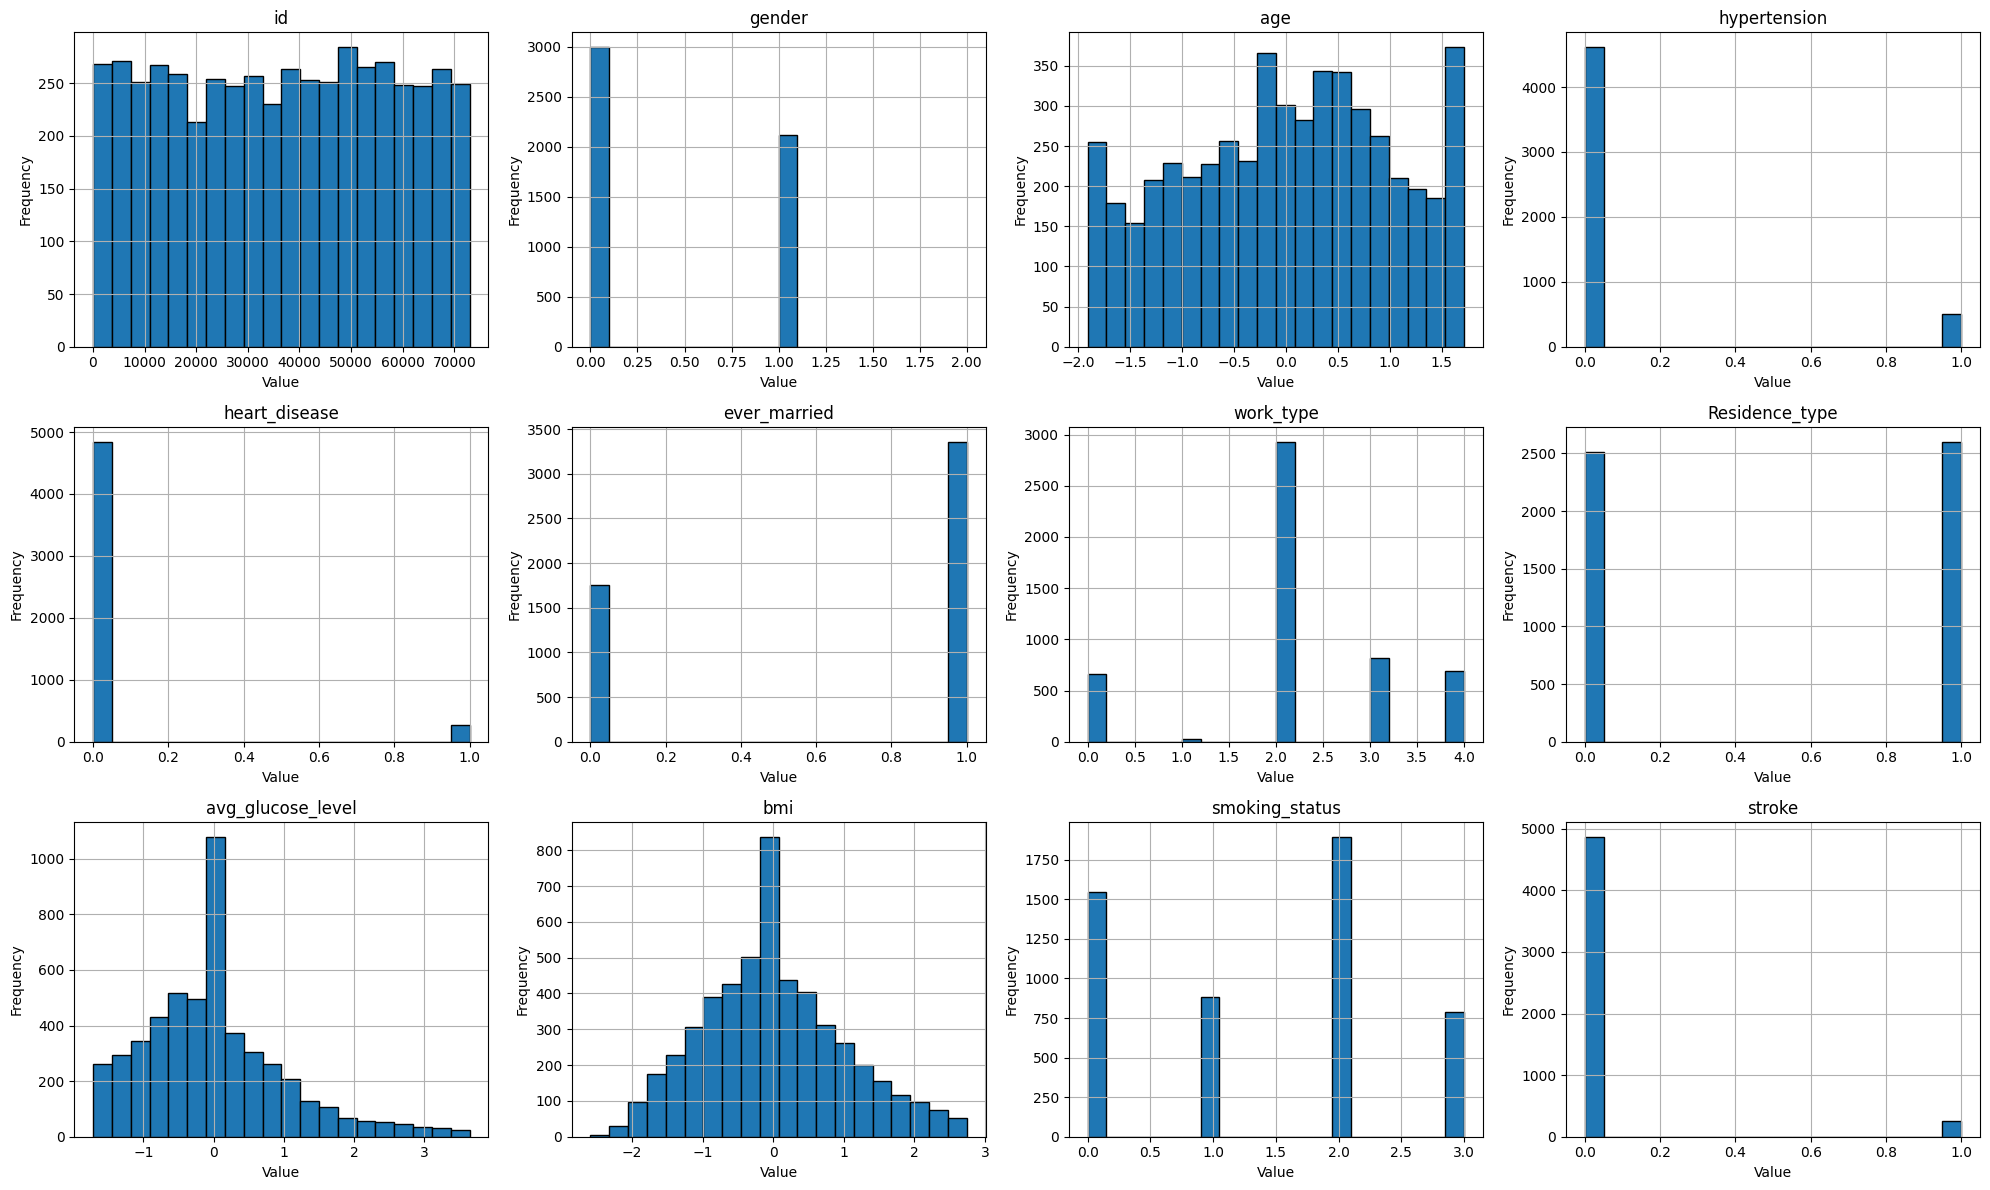

In [33]:
num_vars = df_lencoder.shape[1]

n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [34]:
print(df.columns)

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='str')


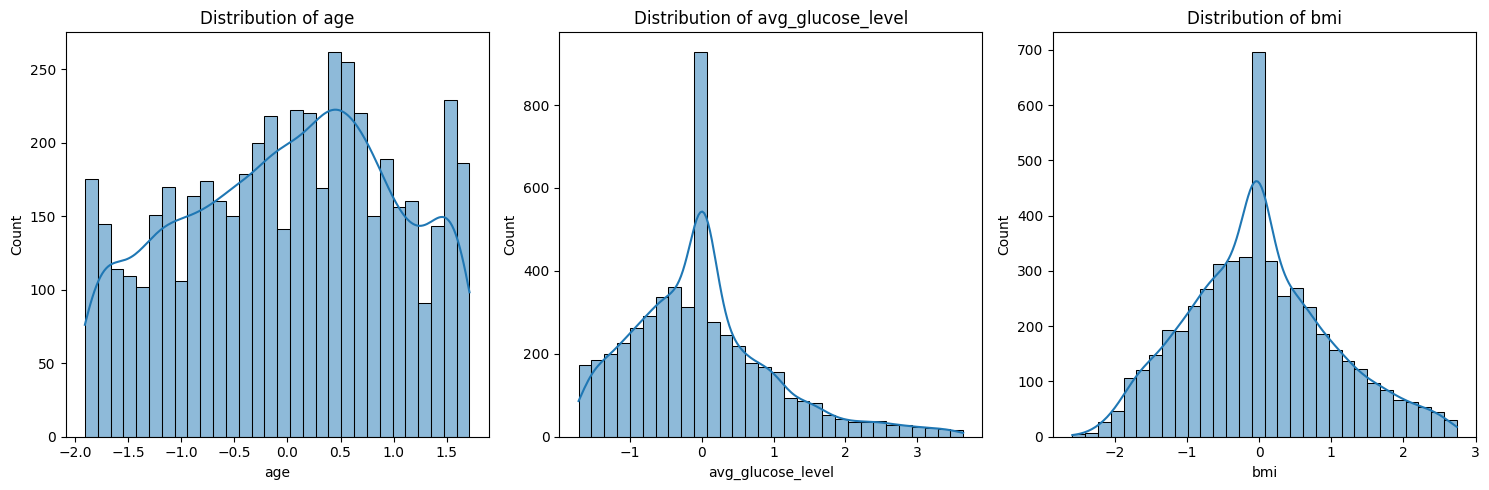

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

columns_to_plot = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(15, 5))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

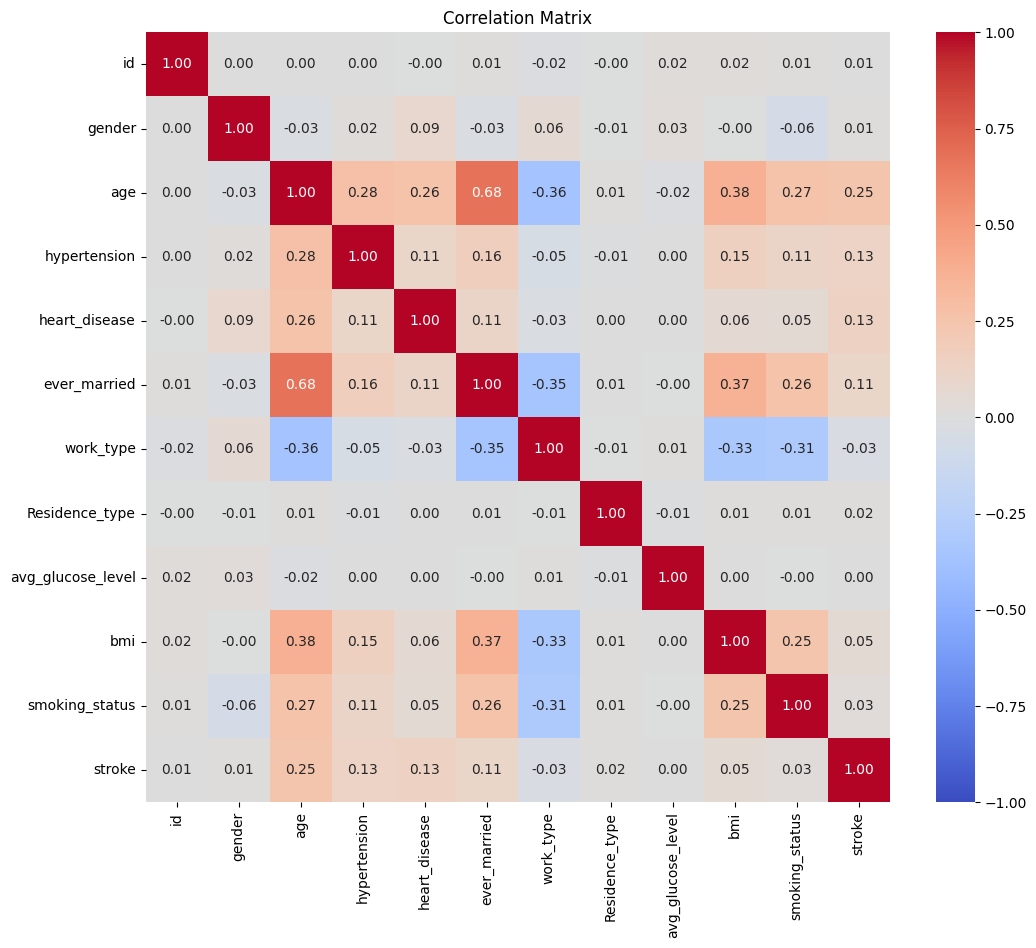

In [36]:
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

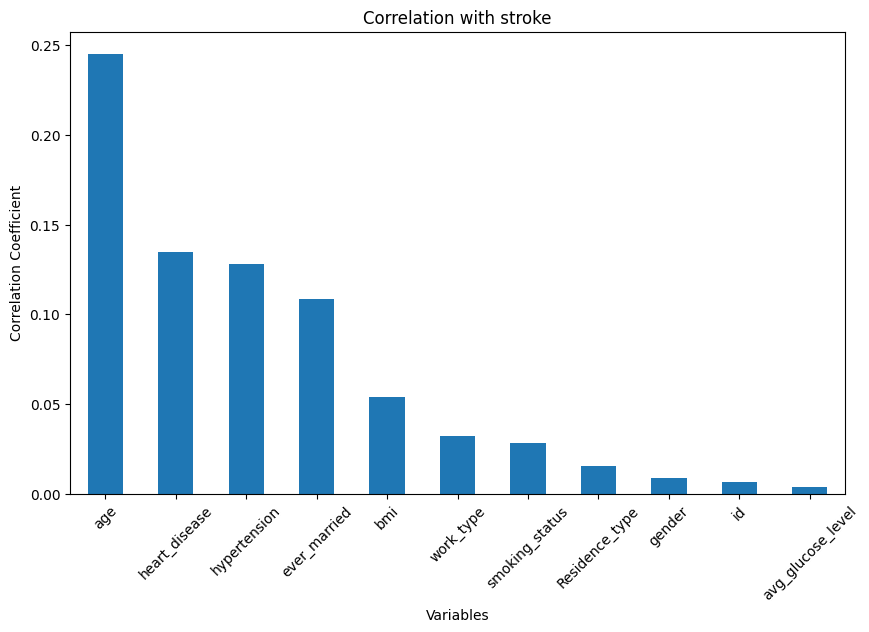

In [37]:
target_corr = df_lencoder.corr()['stroke'].drop('stroke')

target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with stroke')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=45)
plt.show()

In [38]:
import sklearn

# memisahkan fitur (x) dan target (y)

In [39]:
x = df_lencoder.drop(columns=['stroke', 'id'], errors='ignore')
y = df_lencoder['stroke']

In [40]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing

In [41]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.4, random_state=1, stratify=y)

In [42]:
# menghitung panjang/jumlah data
print("Jumlah Data: ", len(x))
# menghitung panjang/jumlah data pada x_train
print("Jumlah Data Latih: ", len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah Data Test: ", len(x_test))

Jumlah Data:  5110
Jumlah Data Latih:  3066
Jumlah Data Test:  2044


# Menghitung jumlah data kosong pada setiap kolom

In [43]:
print("Jumlah NaN pada X_train:")
print(x_train.isna().sum())

print("\nJumlah NaN pada y_train:")
print(y_train.isna().sum())

Jumlah NaN pada X_train:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
dtype: int64

Jumlah NaN pada y_train:
0


In [44]:
from sklearn.impute import SimpleImputer

# Mengisi nilai kosong berdasarkan median data pelatihan
imputer = SimpleImputer(strategy="median")

x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

# Memastikan tidak ada NaN pada data fitur
import numpy as np

print("NaN pada X_train:", np.isnan(x_train).sum())
print("NaN pada X_test:", np.isnan(x_test).sum())

NaN pada X_train: 0
NaN pada X_test: 0


# Melatih model 1 dengan algoritma Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression(max_iter=1000).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Decision Tree Classifier

In [46]:
from sklearn.tree import DecisionTreeClassifier
DT = DecisionTreeClassifier(random_state=184).fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Classifier

In [47]:
from sklearn.ensemble import GradientBoostingClassifier
GBC = GradientBoostingClassifier(random_state=184)
GBC.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",184
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

In [48]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluasi pada model Logistic Regression

In [49]:
pred_LR = LR.predict(x_test)
acc_LR = accuracy_score(y_test, pred_LR)
prec_LR = precision_score(y_test, pred_LR, zero_division=0)
rec_LR = recall_score(y_test, pred_LR, zero_division=0)
f1_LR = f1_score(y_test, pred_LR, zero_division=0)

In [50]:
# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'Accuracy': [acc_LR],
    'Precision': [prec_LR],
    'Recall': [rec_LR],
    'F1-Score': [f1_LR]
}

In [51]:
# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Logistic Regression'])
df_results

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.951076,0.0,0.0,0.0


# Evaluasi pada model Decision Tree

In [52]:
pred_DT = DT.predict(x_test)
acc_DT = accuracy_score(y_test, pred_DT)
prec_DT = precision_score(y_test, pred_DT, zero_division=0)
rec_DT = recall_score(y_test, pred_DT, zero_division=0)
f1_DT = f1_score(y_test, pred_DT, zero_division=0)

In [53]:
# Menambahkan hasil evaluasi DT ke DataFrame
df_results.loc['Decision Tree'] = [acc_DT, prec_DT, rec_DT, f1_DT]
df_results

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.951076,0.000000,0.00,0.000000
Decision Tree,0.898239,0.102941,0.14,0.118644


In [54]:
# Evaluasi pada model Gradient Boosting Classifier
pred_GBC = GBC.predict(x_test)
acc_GBC = accuracy_score(y_test, pred_GBC)
prec_GBC = precision_score(y_test, pred_GBC, zero_division=0)
rec_GBC = recall_score(y_test, pred_GBC, zero_division=0)
f1_GBC = f1_score(y_test, pred_GBC, zero_division=0)

# Menambahkan hasil evaluasi GBC ke DataFrame
df_results.loc['Gradient Boosting Classifier'] = [acc_GBC, prec_GBC, rec_GBC, f1_GBC]
df_results

,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.951076,0.000000,0.00,0.000000
Decision Tree,0.898239,0.102941,0.14,0.118644
Gradient Boosting Classifier,0.948630,0.142857,0.01,0.018692


In [55]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBC, 'gbc_model.joblib')

['gbc_model.joblib']

In [56]:
import pickle

# Menyimpan model ke dalam file
with open('gbc_model.pkl', 'wb') as file:
    pickle.dump(GBC, file)

In [57]:
import os
print("Folder notebook:", os.getcwd())
print([f for f in os.listdir() if f.endswith(('.joblib', '.pkl'))])

Folder notebook: C:\Users\arsya\Downloads\Kampus\Semester 5\Machine Learning\Stroke Prediction Dataset (fedesoriano)
['gbc_model.joblib', 'gbc_model.pkl']


In [58]:
import sklearn, joblib
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.9.1
joblib: 1.5.3


In [60]:
x_test.shape

(2044, 10)

In [61]:
import json
import numpy as np

sample = np.asarray(x_test)[:1].tolist()   # 1 baris, 10 angka

with open("data.json", "w") as f:
    json.dump({"data": sample}, f)

print(sample)

[[0.0, 0.12265954361005779, 0.0, 0.0, 0.0, 3.0, 0.0, -1.2925040330185198, -0.4504128883468859, 2.0]]


In [62]:
%pip install flask


   ---------------------------------------- 0/5 [werkzeug]
   ---------------------------------------- 0/5 [werkzeug]
   ---------------------------------------- 0/5 [werkzeug]
   ---------------------------------------- 0/5 [werkzeug]
   ---------------------------------------- 0/5 [werkzeug]
   ---------------------------------------- 0/5 [werkzeug]
   ---------------------------------------- 0/5 [werkzeug]
   -------- ------------------------------- 1/5 [itsdangerous]
   -------- ------------------------------- 1/5 [itsdangerous]
   ---------------- ----------------------- 2/5 [click]
   ---------------- ----------------------- 2/5 [click]
   ---------------- ----------------------- 2/5 [click]
   -------------------------------- ------- 4/5 [flask]
   -------------------------------- ------- 4/5 [flask]
   -------------------------------- ------- 4/5 [flask]
   -------------------------------- ------- 4/5 [flask]
   -------------------------------- ------- 4/5 [flask]
   ---------